# HW2 part 1: cleaning `ohlc_hw`

Dev Rao

Plan for this notebook:
1. load the raw `ohlc_hw` table and look at it
2. normalize tickers + drop duplicates (has to happen before any grouping)
3. run all the checks and build the data quality report (diagnosis is kept from **before** any repair)
4. repair what I can defend, quarantine what I can't
5. validate and save `ohlc_hw_cleaned` to my local copy of the db

The raw table is never modified. I only read from it and write new tables into a local copy at `data/data.db` (gitignored, never committed).

In [1]:
import re
import shutil
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 25)
plt.style.use('seaborn-v0_8-whitegrid')

### database location

The course db is distributed on bCourses. I check the two places it might be (repo root, or `Lectures/Lecture 4/data/`) and copy it to `data/data.db` next to this notebook if there's no working copy yet. Everything I write goes into that copy, the original file is only read once for the copy.

In [2]:
course_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
hw_dir = course_root / 'Homeworks' / 'HW2' / 'dev_rao'
db_path = hw_dir / 'data' / 'data.db'

if not db_path.is_file():
    candidates = [course_root / 'data.db', course_root / 'Lectures' / 'Lecture 4' / 'data' / 'data.db']
    source_db = next((p for p in candidates if p.is_file()), None)
    if source_db is None:
        raise FileNotFoundError('download data.db from bCourses into Lectures/Lecture 4/data/ (or the repo root)')
    db_path.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(source_db, db_path)
    print('copied', source_db, '->', db_path)

conn = sqlite3.connect(db_path)
print('working db:', db_path)
display(pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name", conn))

copied D:\Berkeley\Pre-Program Courses\Python\UCB-MFE-python-preprogram-2026-winter\data.db -> D:\Berkeley\Pre-Program Courses\Python\UCB-MFE-python-preprogram-2026-winter\Homeworks\HW2\dev_rao\data\data.db
working db: D:\Berkeley\Pre-Program Courses\Python\UCB-MFE-python-preprogram-2026-winter\Homeworks\HW2\dev_rao\data\data.db


,name
0,market_caps
1,ohlc
2,ohlc_hw


## 1.1 load and inspect

In [3]:
raw = pd.read_sql_query('SELECT * FROM ohlc_hw', conn)
raw_row_count = len(raw)
raw.info()
display(raw.describe())
display(raw.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397711 entries, 0 to 397710
Data columns (total 8 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   ts         397711 non-null  object 
 1   open       397711 non-null  float64
 2   high       397711 non-null  float64
 3   low        397711 non-null  float64
 4   close      397711 non-null  float64
 5   adj_close  377856 non-null  float64
 6   volume     397711 non-null  int64  
 7   ticker     397711 non-null  object 
dtypes: float64(5), int64(1), object(2)
memory usage: 24.3+ MB


,open,high,low,close,adj_close,volume
count,397711.000000,397711.000000,397711.000000,397711.000000,377856.000000,3.977110e+05
mean,46.285479,46.747660,45.816279,46.292903,51.652250,3.097773e+07
std,67.132594,67.778210,66.477178,67.141879,194.584045,1.266237e+08
min,0.000000,0.005208,0.004801,0.005208,0.002945,0.000000e+00
25%,4.209938,4.240000,4.160000,4.200000,1.390000,1.730700e+06
50%,19.850000,20.060000,19.630000,19.860000,11.960000,4.648200e+06
75%,57.530000,58.130000,56.950000,57.530000,43.770000,1.102380e+07
max,604.260000,608.630000,597.880000,605.400000,10442.510783,9.276606e+09


,ts,open,high,low,close,adj_close,volume,ticker
0,1975-04-14,5.4300,5.4800,5.3600,5.4400,1.640000,446392,CAT
1,1978-04-05,4.8400,4.8900,4.8100,4.8800,0.656990,355200,CVX
2,2018-05-25,124.5400,124.7600,121.2200,122.1900,92.220000,8936649,CVX
3,1995-12-07,9.9700,9.9700,9.8300,9.9400,5.880000,3954150,HD
4,1981-07-23,0.1038,0.1038,0.1038,0.1038,0.080013,34451232,AAPL


what the columns are:

| column | meaning |
|---|---|
| `ts` | trading date (stored as text `YYYY-MM-DD`) |
| `ticker` | stock symbol, but dirty (html tags, spaces, case) |
| `open`, `high`, `low`, `close` | raw daily prices |
| `adj_close` | vendor adjusted close (splits + dividends), use this for returns |
| `volume` | shares traded that day |

The describe() already shows a couple of things: `adj_close` has nulls and its max is way bigger than the max `close`, which shouldn't happen for a back-adjusted price. `open` has a min of 0.

In [4]:
print('date range:', raw['ts'].min(), 'to', raw['ts'].max())
print('raw ticker strings:', raw['ticker'].nunique())
print('some examples:')
for label in raw['ticker'].drop_duplicates().sample(6, random_state=0):
    print('  ', repr(label))

date range: 1962-01-02 to 2024-12-06
raw ticker strings: 150
some examples:
   '<a target="_blank"><span style="font-weight: bold; color: blue">TRV</span></a>'
   '<a target="_blank"><span style="font-weight: bold; color: blue">AMZN</span></a>'
   'WMT'
   '<a target="_blank"><span style="color: blue">CRM</span></a>'
   '<a target="_blank"><span style="color: blue">CSCO</span></a>'
   '<a target="_blank"><span style="font-weight: bold; color: blue">JNJ</span></a>'


### normalize tickers first

The same stock shows up under several labels (`AAPL`, `<a ...><span ...>AAPL</span></a>`, ` aapl ` etc). If I grouped or deduped before fixing this, one stock would be split into several "stocks" and duplicates wouldn't line up. So: strip html tags, strip whitespace, uppercase. I keep the original label in `raw_ticker` as the audit trail.

In [5]:
def normalize_ticker(labels: pd.Series) -> pd.Series:
    # drop html tags, then whitespace, then uppercase
    return (labels.astype('string')
            .str.replace(r'<[^>]+>', '', regex=True)
            .str.strip()
            .str.upper())


df = raw.rename(columns={'ticker': 'raw_ticker'})
df['ticker'] = normalize_ticker(df['raw_ticker'])

label_audit = df.groupby(['ticker', 'raw_ticker']).size().rename('rows').reset_index()
print('raw labels:', df['raw_ticker'].nunique(), '-> clean tickers:', df['ticker'].nunique())
print(sorted(df['ticker'].unique()))
print('labels per ticker:', label_audit.groupby('ticker').size().value_counts().to_dict())
display(label_audit[label_audit['ticker'] == 'AAPL'])
assert df['ticker'].str.fullmatch(r'[A-Z]+').all()

raw labels: 150 -> clean tickers: 30
['AAPL', 'AMGN', 'AMZN', 'AXP', 'BA', 'CAT', 'CRM', 'CSCO', 'CVX', 'DIS', 'GS', 'HD', 'HON', 'IBM', 'JNJ', 'JPM', 'KO', 'MCD', 'MMM', 'MRK', 'MSFT', 'NKE', 'NVDA', 'PG', 'SHW', 'TRV', 'UNH', 'V', 'VZ', 'WMT']
labels per ticker: {5: 30}


,ticker,raw_ticker,rows
0,AAPL,"<a target=""_blank""><span style=""color: blue"">A...",307
1,AAPL,"<a target=""_blank""><span style=""color: red"">AA...",318
2,AAPL,"<a target=""_blank""><span style=""font-weight: b...",306
3,AAPL,"<a target=""_blank""><span style=""font-weight: b...",264
4,AAPL,AAPL,10747


### duplicates

Exact duplicate = same ticker, date and every value. Those are safe to drop. A *conflicting* duplicate (same ticker/date, different numbers) would need a rule for which source to trust, so I check for those separately instead of just keeping the first one.

In [6]:
value_cols = ['ts', 'ticker', 'open', 'high', 'low', 'close', 'adj_close', 'volume']
exact_dup = df.duplicated(value_cols)
n_exact_dups = int(exact_dup.sum())
print('exact duplicate rows:', n_exact_dups)

df = df.loc[~exact_dup].copy()
conflicts = df[df.duplicated(['ticker', 'ts'], keep=False)]
print('conflicting (ticker, ts) rows left:', len(conflicts))
assert conflicts.empty, 'need a source-selection rule for these'

df['ts'] = pd.to_datetime(df['ts'], format='%Y-%m-%d')
df = df.sort_values(['ticker', 'ts']).reset_index(drop=True)
print('rows after dedup:', len(df))

exact duplicate rows: 29460
conflicting (ticker, ts) rows left: 0
rows after dedup: 368251


Zero conflicting keys, so after dropping exact copies every (ticker, ts) is unique. Every duplicate was also an exact copy of the raw label, so dropping them doesn't lose any label info either.

## 1.2 detecting data quality issues

### missing values (cells)

In [7]:
print('missing cells per column (after dedup):')
display(df.isna().sum().to_frame('missing'))
print('non-finite numbers (inf):', int(np.isinf(df.select_dtypes('number')).sum().sum()))
adj_missing_by_ticker = df.groupby('ticker')['adj_close'].apply(lambda s: s.isna().sum())
display(adj_missing_by_ticker.describe().to_frame('missing adj_close per ticker').T)

missing cells per column (after dedup):


,missing
ts,0
open,0
high,0
low,0
close,0
adj_close,18374
volume,0
raw_ticker,0
ticker,0


non-finite numbers (inf): 0


,count,mean,std,min,25%,50%,75%,max
missing adj_close per ticker,30.0,612.466667,190.512147,228.0,489.0,657.5,782.75,831.0


All the nulls are in `adj_close`. Raw OHLC and volume have none.

### missing trading days (rows)

`.isna()` can't find a row that isn't there at all. For a calendar I use each ticker's dates in the supplied `ohlc` table over that ticker's history (the hw says that's acceptable). I didn't use plain weekdays because those include exchange holidays, which would show up as fake gaps.

In [8]:
reference_keys = pd.read_sql_query('SELECT ticker, ts FROM ohlc', conn)
reference_keys['ts'] = pd.to_datetime(reference_keys['ts'], format='%Y-%m-%d')


def missing_sessions(frame: pd.DataFrame, expected_dates) -> pd.DatetimeIndex:
    # expected dates that don't show up in this ticker's rows
    observed = pd.DatetimeIndex(frame['ts'].dropna().unique())
    return pd.DatetimeIndex(expected_dates).difference(observed).sort_values()


def find_missing_days(data: pd.DataFrame, reference: pd.DataFrame) -> pd.DataFrame:
    # one summary row per ticker, using the reference dates for that ticker
    expected_by_ticker = reference.groupby('ticker')['ts']
    rows = []
    for ticker, rows_for_ticker in data.groupby('ticker'):
        expected = expected_by_ticker.get_group(ticker) if ticker in expected_by_ticker.groups else pd.Series(dtype='datetime64[ns]')
        missing = missing_sessions(rows_for_ticker, expected)
        rows.append({'ticker': ticker,
                     'start': expected.min() if len(expected) else rows_for_ticker['ts'].min(),
                     'end': expected.max() if len(expected) else rows_for_ticker['ts'].max(),
                     'missing_days': len(missing),
                     'missing_dates': list(missing)})
    return pd.DataFrame(rows)


def gap_issue_rows(gap_summary: pd.DataFrame) -> pd.DataFrame:
    # each missing date becomes its own issue row
    exploded = gap_summary.explode('missing_dates').dropna(subset=['missing_dates'])
    return pd.DataFrame({
        'ticker': exploded['ticker'],
        'issue_type': 'missing_trading_day',
        'issue_date': pd.to_datetime(exploded['missing_dates']),
        'description': 'date is in the reference calendar but has no row',
        'severity': 'medium',
    }).reset_index(drop=True)


gap_summary = find_missing_days(df, reference_keys)
for row in gap_summary.head(5).itertuples():
    print(f'Ticker {row.ticker} is missing {row.missing_days} trading days between {row.start.date()} and {row.end.date()}')
print('...')
print('total missing trading days across all tickers:', gap_summary['missing_days'].sum())
gap_issues = gap_issue_rows(gap_summary)

Ticker AAPL is missing 0 trading days between 1980-12-12 and 2024-10-18
Ticker AMGN is missing 0 trading days between 1983-06-17 and 2024-10-18
Ticker AMZN is missing 0 trading days between 1997-05-15 and 2024-12-06
Ticker AXP is missing 0 trading days between 1972-04-03 and 2024-10-18
Ticker BA is missing 0 trading days between 1962-01-02 and 2024-10-18
...
total missing trading days across all tickers: 0


Zero missing days, which is a legit result. The check still has to work though, so here's a tiny test: take 6 AAPL dates, delete one, and make sure the detector finds exactly that date.

In [9]:
demo_calendar = reference_keys[reference_keys['ticker'] == 'AAPL'].head(6)
demo_rows = demo_calendar.drop(demo_calendar.index[3])  # remove the 4th date on purpose
demo_gaps = find_missing_days(demo_rows, demo_calendar)
removed_date = demo_calendar['ts'].iloc[3]
row = demo_gaps.iloc[0]
print(f'Ticker {row.ticker} is missing {row.missing_days} trading days between {row.start.date()} and {row.end.date()}: {[d.date() for d in row.missing_dates]}')
assert row.missing_days == 1 and row.missing_dates[0] == removed_date
display(gap_issue_rows(demo_gaps))

Ticker AAPL is missing 1 trading days between 2022-04-12 and 2023-10-13: [datetime.date(2022, 4, 14)]


,ticker,issue_type,issue_date,description,severity
0,AAPL,missing_trading_day,2022-04-14,date is in the reference calendar but has no row,medium


### outliers, impossible prices, inconsistencies

All the row-level checks live in one function, the same masks -> rows -> concat idea from lecture, just with more checks. One row can trip several checks, so it can show up more than once in the report.

- **extreme return**: simple return on raw close, `abs(r - mean) > 3 * std` per ticker, `ddof=1`, both tails. The first return for each ticker (undefined) is excluded, and a ticker with zero/undefined std gets no flags. This is only a review flag, not a delete rule.
- **close outside range**: `high < close` or `low > close`
- **open outside range / high < low**: the rest of `low <= open <= high`
- **nonpositive / non-finite price**: OHLC and adj_close (raw bounds don't apply to adj_close since it's on a different scale)
- **missing adj_close**
- **adj factor jump**: this one wasn't on the checklist but the data needs it. `adj_close / close` is the adjustment factor and it should be basically flat, only stepping at splits/dividends. A single row whose factor is way off its neighbours (log difference > 0.5 vs the rolling 21-row median, so ~1.65x) means a bad adj_close
- **zero volume** and **invalid volume** (missing, negative, inf)

Severity:
- **high** = the value is wrong or missing and would break returns/report (bad prices, bounds violations, missing or corrupted adj_close). Must be fixed or quarantined
- **medium** = needs a human look but could be real (3 sigma moves, missing trading days, unknown volume)
- **low** = suspicious but harmless for the report (zero volume, maybe stale data)

In [10]:
PRICE_COLS = ['open', 'high', 'low', 'close']


def fmt(s: pd.Series, spec: str = '{:.4f}') -> pd.Series:
    return s.map(lambda v: 'nan' if pd.isna(v) else spec.format(v))


def adj_factor_deviation(data: pd.DataFrame) -> pd.DataFrame:
    # log(adj/close) and how far it sits from the rolling median of neighbours (same ticker)
    factor = data['adj_close'] / data['close']
    log_factor = np.log(factor.where(np.isfinite(factor) & factor.gt(0)))
    neighbour_median = log_factor.groupby(data['ticker']).transform(
        lambda s: s.rolling(21, center=True, min_periods=5).median())
    return pd.DataFrame({'factor': factor,
                         'neighbour_factor': np.exp(neighbour_median),
                         'log_dev': (log_factor - neighbour_median).abs()})


def simple_return_stats(data: pd.DataFrame) -> pd.DataFrame:
    # simple returns on raw close within ticker + the 3 sigma screen
    valid_close = data['close'].where(np.isfinite(data['close']) & data['close'].gt(0))
    ret = valid_close.groupby(data['ticker']).pct_change(fill_method=None)
    grouped = ret.groupby(data['ticker'])
    mean, std = grouped.transform('mean'), grouped.transform('std')  # std is ddof=1
    usable = ret.notna() & np.isfinite(std) & std.gt(0)
    flag = usable & (ret - mean).abs().gt(3 * std)
    return pd.DataFrame({'ret': ret, 'mean': mean, 'std': std, 'z': (ret - mean) / std, 'flag': flag})


def price_issue_report(frame: pd.DataFrame) -> pd.DataFrame:
    # needs normalized tickers + unique (ticker, ts). returns one row per issue found
    data = frame.sort_values(['ticker', 'ts']).reset_index(drop=True)
    prices = data[PRICE_COLS + ['adj_close']]
    rs = simple_return_stats(data)
    adj = adj_factor_deviation(data)
    nonpositive = (prices.le(0) | np.isinf(prices)).any(axis=1)

    checks = {
        'missing_price': (data[PRICE_COLS].isna().any(axis=1), 'high',
                          lambda d: 'missing raw price in: ' + d[PRICE_COLS].isna().apply(lambda r: ', '.join(r.index[r]), axis=1)),
        'missing_adj_close': (data['adj_close'].isna(), 'high',
                              lambda d: 'adj_close is null (raw close ' + fmt(d['close']) + ')'),
        'nonpositive_price': (nonpositive, 'high',
                              lambda d: 'nonpositive/non-finite price: ' + d[PRICE_COLS + ['adj_close']].apply(
                                  lambda r: ', '.join(f'{k}={v}' for k, v in r.items() if not (np.isfinite(v) and v > 0) and pd.notna(v)), axis=1)),
        'close_outside_range': (data['high'].lt(data['close']) | data['low'].gt(data['close']), 'high',
                                lambda d: 'close ' + fmt(d['close']) + ' outside [low, high] = [' + fmt(d['low']) + ', ' + fmt(d['high']) + ']'),
        'open_outside_range': (data['high'].lt(data['open']) | data['low'].gt(data['open']) | data['high'].lt(data['low']), 'high',
                               lambda d: 'open ' + fmt(d['open']) + ' outside [low, high] = [' + fmt(d['low']) + ', ' + fmt(d['high']) + '] (or high < low)'),
        'adj_factor_jump': (adj['log_dev'].gt(0.5), 'high',
                            lambda d: 'adj/close factor ' + fmt(adj.loc[d.index, 'factor']) + ' vs neighbour median '
                                      + fmt(adj.loc[d.index, 'neighbour_factor']) + ' ('
                                      + fmt(adj.loc[d.index, 'factor'] / adj.loc[d.index, 'neighbour_factor'], '{:.1f}') + 'x off)'),
        'extreme_return': (rs['flag'], 'medium',
                           lambda d: 'simple return ' + fmt(rs.loc[d.index, 'ret'] * 100, '{:+.2f}') + '% vs ticker mean '
                                     + fmt(rs.loc[d.index, 'mean'] * 100, '{:.3f}') + '%, std ' + fmt(rs.loc[d.index, 'std'] * 100, '{:.2f}')
                                     + '% (z = ' + fmt(rs.loc[d.index, 'z'], '{:.1f}') + ')'),
        'invalid_volume': (data['volume'].isna() | np.isinf(data['volume']) | data['volume'].lt(0), 'medium',
                           lambda d: 'volume is ' + fmt(d['volume'], '{}') + ' (unknown volume)'),
        'zero_volume': (data['volume'].eq(0), 'low',
                        lambda d: 'zero volume, possibly stale quote'),
    }
    parts = []
    for issue, (mask, severity, describe) in checks.items():
        hit = data.loc[mask.fillna(False)]
        if hit.empty:
            continue
        parts.append(pd.DataFrame({'ticker': hit['ticker'], 'issue_type': issue, 'issue_date': hit['ts'],
                                   'description': describe(hit), 'severity': severity}))
    cols = ['ticker', 'issue_type', 'issue_date', 'description', 'severity']
    if not parts:
        return pd.DataFrame(columns=cols)
    return pd.concat(parts, ignore_index=True)[cols]

Before running it on the real data, here's a quick test on a tiny made-up frame. It has one of each problem that **doesn't** actually show up in our db (high < close, low > close, negative adj_close, missing/negative volume, an inf price), so I can see each detector actually fire.

In [11]:
demo = pd.DataFrame({
    'ticker': ['DEMO'] * 6,
    'ts': pd.bdate_range('2024-01-02', periods=6),
    'open':      [10.0, 10.2, 10.1, 10.3, 10.2, 10.4],
    'high':      [10.5, 10.4, 10.6, 10.5, 10.6, np.inf],
    'low':       [ 9.8, 10.0, 10.0, 10.1, 10.0, 10.1],
    'close':     [10.2, 10.6, 10.3,  9.9, 10.4, 10.3],   # day 2 close > high, day 4 close < low
    'adj_close': [10.2, 10.6, -1.0,  9.9, 10.4, 10.3],   # day 3 adj negative
    'volume':    [1e6, 2e6, np.nan, -5.0, 0.0, 1e6],
})
demo_report = price_issue_report(demo)
display(demo_report)
assert {'close_outside_range', 'nonpositive_price', 'invalid_volume', 'zero_volume'} <= set(demo_report['issue_type'])

,ticker,issue_type,issue_date,description,severity
0,DEMO,nonpositive_price,2024-01-04,nonpositive/non-finite price: adj_close=-1.0,high
1,DEMO,nonpositive_price,2024-01-09,nonpositive/non-finite price: high=inf,high
2,DEMO,close_outside_range,2024-01-03,"close 10.6000 outside [low, high] = [10.0000, ...",high
3,DEMO,close_outside_range,2024-01-05,"close 9.9000 outside [low, high] = [10.1000, 1...",high
4,DEMO,invalid_volume,2024-01-04,volume is nan (unknown volume),medium
5,DEMO,invalid_volume,2024-01-05,volume is -5.0 (unknown volume),medium
6,DEMO,zero_volume,2024-01-08,"zero volume, possibly stale quote",low


Works. Now the real thing, on the deduped data, **before** any repairs (this is the diagnosis I keep).

In [12]:
row_issues = price_issue_report(df)
quality_report = pd.concat([part for part in [row_issues, gap_issues] if not part.empty], ignore_index=True)
quality_report = quality_report.sort_values(['ticker', 'issue_date', 'issue_type']).reset_index(drop=True)

print('total issue rows:', len(quality_report))
display(quality_report.groupby(['severity', 'issue_type']).size().rename('issues').to_frame())
display(quality_report.groupby('issue_type').head(2).reset_index(drop=True))

total issue rows: 33932


issues
severity issue_type                
high     adj_factor_jump      10417
         missing_adj_close    18374
         nonpositive_price        5
         open_outside_range       5
low      zero_volume             75
medium   extreme_return        5056

,ticker,issue_type,issue_date,description,severity
0,AAPL,extreme_return,1980-12-26,"simple return +9.23% vs ticker mean 0.107%, st...",medium
1,AAPL,missing_adj_close,1981-01-08,adj_close is null (raw close 0.1351),high
2,AAPL,missing_adj_close,1981-01-13,adj_close is null (raw close 0.1362),high
3,AAPL,adj_factor_jump,1981-02-03,adj/close factor 10.2537 vs neighbour median 0...,high
4,AAPL,extreme_return,1981-04-02,"simple return +8.77% vs ticker mean 0.107%, st...",medium
5,AAPL,adj_factor_jump,1981-04-28,adj/close factor 16.1485 vs neighbour median 0...,high
6,AXP,zero_volume,1972-12-14,"zero volume, possibly stale quote",low
7,CVX,nonpositive_price,1962-01-02,nonpositive/non-finite price: open=0.0,high
8,CVX,open_outside_range,1962-01-02,"open 0.0000 outside [low, high] = [3.2400, 3.3...",high
9,HON,zero_volume,1982-09-23,"zero volume, possibly stale quote",low


In [13]:
issue_counts = quality_report.pivot_table(index='ticker', columns='issue_type', values='issue_date', aggfunc='count', fill_value=0)
display(issue_counts)

issue_type,adj_factor_jump,extreme_return,missing_adj_close,nonpositive_price,open_outside_range,zero_volume
ticker,,,,,,
AAPL,329,143,575,0,0,0
AMGN,298,172,492,0,0,0
AMZN,200,147,328,0,0,0
AXP,383,199,644,0,0,1
BA,465,210,820,0,0,0
CAT,459,221,831,0,0,0
CRM,165,82,250,0,0,0
CSCO,252,148,433,0,0,0
CVX,441,178,817,1,1,0


What came out:
- **missing_adj_close**: about 18k rows, spread over all tickers and all years, including the 2024 report window
- **adj_factor_jump**: ~10k rows where adj_close is 4x-24x too big. The factor should be < 1 for back-adjusted prices, these are > 1. The raw close is fine on those rows, only adj_close is off
- **nonpositive_price + open_outside_range**: the same 5 rows, open = 0 on each ticker's very first day (1960s). Looks like a placeholder for "no open recorded"
- **zero_volume**: 75 rows, all 1962-1982, mostly WMT. Old, thin data, I'll just flag them
- **extreme_return**: thousands of 3 sigma flags, which is normal for 60 years of daily data (fat tails). Need to look at the big ones
- nothing for missing prices, close outside range, invalid volume or missing trading days. The demos above show those checks do work

### investigating the extreme returns

3 sigma flags way too much to look at one by one, so I sort by |z| and look at the top ones with some context: did the price come straight back the next day? what happened to volume? are O/H/L/C all identical (a flat row is a sign of a filler quote)?

In [14]:
rs = simple_return_stats(df)
ctx = df[['ticker', 'ts', 'open', 'high', 'low', 'close', 'volume']].copy()
ctx['ret'] = rs['ret']
ctx['z'] = rs['z']
g = df.groupby('ticker')['close']
ctx['next_vs_prev_close'] = g.shift(-1) / g.shift(1) - 1   # ~0 means it reverted the next day
ctx['volume_vs_20d_median'] = df['volume'] / df.groupby('ticker')['volume'].transform(lambda s: s.rolling(20, min_periods=5).median().shift(1))
ctx['flat_ohlc'] = df['open'].eq(df['high']) & df['high'].eq(df['low']) & df['low'].eq(df['close'])
top = ctx[rs['flag']].reindex(ctx[rs['flag']]['z'].abs().sort_values(ascending=False).index).head(15)
display(top.round(4))

,ticker,ts,open,high,low,close,volume,ret,z,next_vs_prev_close,volume_vs_20d_median,flat_ohlc
319538,TRV,1981-08-10,12.0600,12.0600,12.0600,12.0600,0,1.0000,41.2445,0.0000,0.0000,True
318332,TRV,1976-10-28,9.2200,9.2200,9.2200,9.2200,0,1.0000,41.2445,0.0174,0.0000,True
318873,TRV,1978-12-20,8.0300,8.0300,8.0300,8.0300,0,0.9975,41.1419,0.0174,0.0000,True
213788,MCD,1968-01-02,0.1749,0.1749,0.1749,0.1749,6755143,-0.7536,-40.7200,-0.7525,12.0865,True
296654,PG,2000-03-07,28.7800,30.8900,28.4100,29.7800,138294512,-0.3137,-23.1960,-0.3367,25.7786,False
319539,TRV,1981-08-11,6.0300,6.0300,6.0300,6.0300,24800,-0.5000,-20.6578,-0.4917,0.1238,True
293525,PG,1987-10-19,5.1500,5.1500,3.7200,3.8100,25953012,-0.2770,-20.4908,-0.1176,3.3179,False
318333,TRV,1976-10-29,4.6900,4.6900,4.6900,4.6900,79200,-0.4913,-20.2997,-0.4946,0.5000,True
318874,TRV,1978-12-21,4.0900,4.0900,4.0900,4.0900,105600,-0.4907,-20.2723,-0.4907,0.7273,True
4999,AAPL,2000-09-29,0.5034,0.5179,0.4531,0.4598,3128875900,-0.5187,-18.6658,-0.5467,9.4615,False


Three TRV rows (1976-10-28, 1978-12-20, 1981-08-10) stick out:
- the close exactly doubles (+100%) and the very next day it falls right back (next close is within 2% of the day before the spike)
- O=H=L=C on those days and volume is 0

That's not a split (a split doesn't undo itself the next day) and no real news doubles a stock for exactly one day on zero volume. I'm calling these **confirmed data errors**. Interesting detail: the reference `ohlc` table has the same spikes, so I can't fix them from the reference. Plan is to interpolate them from the neighbouring days.

The others I'm keeping, just flagged:
- AAPL 2000-09-29 (-52%) and NVDA 2000-03-07 (+42%) both came with a big volume spike and the price stayed at the new level, so they look like real moves. I'm not claiming a specific news event, I'm just saying nothing in the data says error
- MCD 1968-01-02 (-75%) also stays at the new level with high volume. Might be a split the vendor didn't adjust, but I have no source to confirm that, so I keep it with that uncertainty noted. It's from 1968, nowhere near the 2024 window

Rule I use to flag the confirmed errors: |simple return| > 25% **and** the next close is back within 5% of the pre-spike close. On this data it catches exactly those three TRV rows.

In [15]:
def find_spike_errors(data: pd.DataFrame, min_move: float = 0.25, revert_tol: float = 0.05) -> pd.Series:
    # one day spikes that fully reverse the next day = bad quote
    close = data['close']
    prev_close = close.groupby(data['ticker']).shift(1)
    next_close = close.groupby(data['ticker']).shift(-1)
    move = close / prev_close - 1
    reverted = (next_close / prev_close - 1).abs() < revert_tol
    return (move.abs() > min_move) & reverted


spike_error = find_spike_errors(df)
display(ctx.loc[spike_error].round(4))
assert spike_error.sum() == 3

,ticker,ts,open,high,low,close,volume,ret,z,next_vs_prev_close,volume_vs_20d_median,flat_ohlc
318332,TRV,1976-10-28,9.22,9.22,9.22,9.22,0,1.0000,41.2445,0.0174,0.0,True
318873,TRV,1978-12-20,8.03,8.03,8.03,8.03,0,0.9975,41.1419,0.0174,0.0,True
319538,TRV,1981-08-10,12.06,12.06,12.06,12.06,0,1.0000,41.2445,0.0000,0.0,True


## 1.3 cleaning

Order matters here, so this is what I do and why:

1. **drop rows where all of OHLC are missing**, before filling anything (there are none, but the step is there)
2. **invalid raw prices** (<= 0 / inf) -> NaN. To fill a missing open or close I use the previous close if it's inside today's [low, high], otherwise the midpoint of today's high and low (option 1, forward fill, with a bounds check, because plain ffill can break today's range). If there's no previous close (leading gap) or high/low themselves are bad, the row gets **quarantined** with a reason. The 5 open=0 rows are all first rows, so they end up quarantined
3. **spike errors** (the 3 TRV rows): interpolate O/H/L/C as the midpoint of the day before and after within the ticker. Linear interpolation keeps low <= open/close <= high since both neighbours satisfy it
4. **adj_close**: for missing, nonpositive or factor-jump rows, rebuild adj_close = validated raw close x the date-specific factor from the matching (ticker, ts) row in `ohlc` (factor = ohlc.adj_close / ohlc.close). I only use it when the reference close matches our raw close, so the factor is for the same price. This is a per-row fix, not swapping in the whole reference table. For the 3 spike rows the reference factor is also spiked, so there I interpolate adj_close from the (already repaired) neighbours instead
5. **volume**: missing/negative/inf -> 0 with a flag (unknown volume doesn't mean no trading). Real zero volume days stay as they are, just flagged
6. whatever still fails validation -> quarantine, with a reason

Every repair gets a flag column saved with the table.

In [16]:
clean = df.copy()
quarantine_parts = []


def send_to_quarantine(mask: pd.Series, reason: str) -> None:
    global clean
    if mask.any():
        q = clean.loc[mask].copy()
        q['quarantine_reason'] = reason
        quarantine_parts.append(q)
        clean = clean.loc[~mask].reset_index(drop=True)


# step 1: rows with every raw price missing
all_missing = clean[PRICE_COLS].isna().all(axis=1)
n_all_missing_dropped = int(all_missing.sum())
clean = clean.loc[~all_missing].reset_index(drop=True)
print('rows dropped because all OHLC missing:', n_all_missing_dropped)

rows dropped because all OHLC missing: 0


In [17]:
def repair_raw_prices(data: pd.DataFrame) -> tuple[pd.DataFrame, pd.Series]:
    # invalid open/close -> prev close if inside today's range, else (high+low)/2.
    # returns the data and a mask of rows that can't be repaired
    data = data.copy()
    invalid = ~np.isfinite(data[PRICE_COLS]) | data[PRICE_COLS].le(0)
    data[PRICE_COLS] = data[PRICE_COLS].mask(invalid)
    for col in PRICE_COLS:
        data[f'{col}_repaired'] = False

    # last known close before today (carries over earlier gaps too)
    prev_close = data.groupby('ticker')['close'].transform(lambda s: s.ffill().shift(1))
    range_ok = data['high'].notna() & data['low'].notna() & data['high'].ge(data['low'])
    midpoint = (data['high'] + data['low']) / 2
    candidate = prev_close.where(prev_close.between(data['low'], data['high']), midpoint)
    for col in ['open', 'close']:
        fixable = data[col].isna() & range_ok & prev_close.notna()
        data.loc[fixable, col] = candidate[fixable]
        data.loc[fixable, f'{col}_repaired'] = True

    unresolved = data[PRICE_COLS].isna().any(axis=1)
    return data, unresolved


clean, unresolved_raw = repair_raw_prices(clean)
display(clean.loc[unresolved_raw, ['ticker', 'ts'] + PRICE_COLS + ['adj_close', 'volume']])
send_to_quarantine(unresolved_raw, 'invalid raw price on the first row, no earlier close to repair from')
print('quarantined so far:', sum(len(q) for q in quarantine_parts))

,ticker,ts,open,high,low,close,adj_close,volume
87103,CVX,1962-01-02,NaN,3.30000,3.24000,3.30000,0.335750,105840
167733,JNJ,1962-01-02,NaN,0.22338,0.22222,0.22338,0.064012,0
213412,MCD,1966-07-05,NaN,0.27366,0.26749,0.26955,0.118090,388800
243893,MRK,1962-01-02,NaN,0.39703,0.39317,0.39537,0.068447,633830
287040,PG,1962-01-02,NaN,1.44000,1.42000,1.43000,0.259300,192000


quarantined so far: 5


Quick test of that repair on rows that aren't leading (our real data has none of these). Day 2 has a bad close and yesterday's close is in range, so it gets yesterday's close. Day 3's open is bad and yesterday's close is *outside* today's range, so it gets the midpoint. DEMO2's first row can't be fixed, so it stays unresolved.

In [18]:
repair_demo = pd.DataFrame({
    'ticker': ['DEMO'] * 3 + ['DEMO2'] * 2,
    'ts': list(pd.bdate_range('2024-01-02', periods=3)) + list(pd.bdate_range('2024-01-02', periods=2)),
    'open':  [10.0, 10.1, 0.0, -1.0, 20.0],
    'high':  [10.5, 10.6, 12.0, 21.0, 20.5],
    'low':   [ 9.8,  9.9, 11.0, 19.0, 19.5],
    'close': [10.2, np.nan, 11.5, 20.0, 20.1],
})
fixed_demo, unresolved_demo = repair_raw_prices(repair_demo)
display(fixed_demo.assign(unresolved=unresolved_demo))
assert fixed_demo.loc[1, 'close'] == 10.2 and fixed_demo.loc[2, 'open'] == 11.5
assert unresolved_demo.tolist() == [False, False, False, True, False]

,ticker,ts,open,high,low,close,open_repaired,high_repaired,low_repaired,close_repaired,unresolved
0,DEMO,2024-01-02,10.0,10.5,9.8,10.2,False,False,False,False,False
1,DEMO,2024-01-03,10.1,10.6,9.9,10.2,False,False,False,True,False
2,DEMO,2024-01-04,11.5,12.0,11.0,11.5,True,False,False,False,False
3,DEMO2,2024-01-02,NaN,21.0,19.0,20.0,False,False,False,False,True
4,DEMO2,2024-01-03,20.0,20.5,19.5,20.1,False,False,False,False,False


In [19]:
def interpolate_spikes(data: pd.DataFrame, spike_mask: pd.Series, cols: list[str]) -> pd.DataFrame:
    # midpoint of the previous and next row (same ticker) for the flagged rows only
    data = data.copy()
    for col in cols:
        prev_val = data.groupby('ticker')[col].shift(1)
        next_val = data.groupby('ticker')[col].shift(-1)
        data.loc[spike_mask, col] = ((prev_val + next_val) / 2)[spike_mask]
    return data


# recompute the spike mask on the current (post-quarantine) index
spike_error = find_spike_errors(clean)
clean['spike_repaired'] = spike_error
before_spike = clean.loc[spike_error, ['ticker', 'ts'] + PRICE_COLS].copy()
clean = interpolate_spikes(clean, spike_error, PRICE_COLS)
for col in PRICE_COLS:
    clean[f'{col}_repaired'] |= spike_error
display(before_spike.merge(clean.loc[spike_error, ['ticker', 'ts'] + PRICE_COLS], on=['ticker', 'ts'], suffixes=('_before', '_after')))

,ticker,ts,open_before,high_before,low_before,close_before,open_after,high_after,low_after,close_after
0,TRV,1976-10-28,9.22,9.22,9.22,9.22,4.650,4.650,4.650,4.650
1,TRV,1978-12-20,8.03,8.03,8.03,8.03,4.055,4.055,4.055,4.055
2,TRV,1981-08-10,12.06,12.06,12.06,12.06,6.030,6.030,6.030,6.030


### adj_close repair

The factor from `ohlc` is looked up by exact (ticker, ts), so I never carry a factor forward across a possible split or dividend.

In [20]:
reference_prices = pd.read_sql_query('SELECT ticker, ts, close AS ref_close, adj_close AS ref_adj_close FROM ohlc', conn)
reference_prices['ts'] = pd.to_datetime(reference_prices['ts'], format='%Y-%m-%d')
clean = clean.merge(reference_prices, on=['ticker', 'ts'], how='left', validate='one_to_one')

adj_dev = adj_factor_deviation(clean)
bad_adj = (clean['adj_close'].isna() | ~np.isfinite(clean['adj_close']) | clean['adj_close'].le(0)
           | adj_dev['log_dev'].gt(0.5))
ref_factor = clean['ref_adj_close'] / clean['ref_close']
ref_usable = (np.isfinite(ref_factor) & ref_factor.gt(0)
              & np.isclose(clean['ref_close'], clean['close'], rtol=1e-9))

clean['adj_close_repaired'] = False
clean['adj_close_source'] = 'vendor'

use_ref = bad_adj & ref_usable & ~clean['spike_repaired']
clean.loc[use_ref, 'adj_close'] = clean.loc[use_ref, 'close'] * ref_factor[use_ref]
clean.loc[use_ref, ['adj_close_repaired', 'adj_close_source']] = [True, 'ohlc_factor_x_close']

# spike rows: interpolate adj_close between neighbours (they're fixed now)
clean = interpolate_spikes(clean, clean['spike_repaired'], ['adj_close'])
clean.loc[clean['spike_repaired'], ['adj_close_repaired', 'adj_close_source']] = [True, 'interpolated']

print('adj_close rows flagged bad:', int(bad_adj.sum()))
print(clean['adj_close_source'].value_counts().to_string())
unresolved_adj = bad_adj & ~use_ref & ~clean['spike_repaired']
print('bad adj_close with no trusted factor:', int(unresolved_adj.sum()))

adj_close rows flagged bad: 28793
adj_close_source
vendor                 339453
ohlc_factor_x_close     28790
interpolated                3
bad adj_close with no trusted factor: 0


In [21]:
send_to_quarantine(unresolved_adj, 'adj_close missing/corrupted and no trusted reference factor for that date')

# volume: unknown -> 0 with a flag (none in this data, but the rule is here)
bad_volume = clean['volume'].isna() | np.isinf(clean['volume']) | clean['volume'].lt(0)
clean['volume_repaired'] = bad_volume
clean.loc[bad_volume, 'volume'] = 0
print('volume values set to 0 as a placeholder:', int(bad_volume.sum()))

# review flags that stay with the data (no change to the values)
clean['zero_volume_flag'] = clean['volume'].eq(0) & ~clean['volume_repaired']
clean['extreme_return_flag'] = simple_return_stats(clean)['flag']

volume values set to 0 as a placeholder: 0


Same idea for volume on a tiny example: a missing volume becomes 0, and the flag says it's a placeholder and not a real zero.

In [22]:
vol_demo = pd.DataFrame({'ticker': ['A', 'B', 'C'], 'volume': [100.0, np.nan, -3.0]})
vol_demo['volume_repaired'] = vol_demo['volume'].isna() | vol_demo['volume'].lt(0)
vol_demo.loc[vol_demo['volume_repaired'], 'volume'] = 0
display(vol_demo)

,ticker,volume,volume_repaired
0,A,100.0,False
1,B,0.0,True
2,C,0.0,True


## validation

Everything has to pass these asserts, otherwise the table doesn't get saved.

In [23]:
def validate_clean(data: pd.DataFrame) -> pd.Series:
    # returns a pass/fail series, every value must be True
    p = data[PRICE_COLS + ['adj_close']]
    checks = {
        'no missing prices (raw + adj)': p.notna().all().all(),
        'all prices finite': np.isfinite(p).all().all(),
        'all prices > 0': p.gt(0).all().all(),
        'low <= open <= high': data['open'].between(data['low'], data['high']).all(),
        'low <= close <= high': data['close'].between(data['low'], data['high']).all(),
        'high >= low': data['high'].ge(data['low']).all(),
        'unique (ticker, ts)': not data.duplicated(['ticker', 'ts']).any(),
        'volume finite and >= 0': np.isfinite(data['volume']).all() and data['volume'].ge(0).all(),
        'no adj factor jumps left': not adj_factor_deviation(data)['log_dev'].gt(0.5).any(),
        'sorted by ticker, ts': data['ticker'].is_monotonic_increasing and data.groupby('ticker')['ts'].is_monotonic_increasing.all(),
    }
    return pd.Series(checks, name='passed')


validation = validate_clean(clean)
display(validation.to_frame())
assert validation.all(), validation[~validation]

,passed
no missing prices (raw + adj),True
all prices finite,True
all prices > 0,True
low <= open <= high,True
low <= close <= high,True
high >= low,True
"unique (ticker, ts)",True
volume finite and >= 0,True
no adj factor jumps left,True
"sorted by ticker, ts",True


In [24]:
post_issues = price_issue_report(clean)
print('issues left after cleaning (the 3 sigma ones and zero volume are review flags, not errors):')
print('(3 sigma count goes up a bit vs before: removing the TRV spikes shrinks the TRV std, so more TRV days cross 3 sigma)')
display(post_issues.groupby(['severity', 'issue_type']).size().rename('issues').to_frame())
assert not post_issues['severity'].eq('high').any()

issues left after cleaning (the 3 sigma ones and zero volume are review flags, not errors):
(3 sigma count goes up a bit vs before: removing the TRV spikes shrinks the TRV std, so more TRV days cross 3 sigma)


,,issues
severity,issue_type,
low,zero_volume,74
medium,extreme_return,5176


### before / after

In [25]:
before = df[['open', 'high', 'low', 'close', 'adj_close', 'volume']].describe().T
after = clean[['open', 'high', 'low', 'close', 'adj_close', 'volume']].describe().T
display(pd.concat({'before': before[['count', 'mean', 'min', 'max']], 'after': after[['count', 'mean', 'min', 'max']]}, axis=1).round(4))

quarantine = pd.concat(quarantine_parts, ignore_index=True) if quarantine_parts else pd.DataFrame()
accounting = pd.Series({
    'raw rows in ohlc_hw': raw_row_count,
    'exact duplicates removed': n_exact_dups,
    'all-OHLC-missing rows dropped': n_all_missing_dropped,
    'quarantined': len(quarantine),
    'retained in ohlc_hw_cleaned': len(clean),
})
display(accounting.to_frame('rows'))
assert accounting.iloc[0] == accounting.iloc[1:].sum()
display(quarantine[['ticker', 'ts', 'open', 'high', 'low', 'close', 'adj_close', 'volume', 'quarantine_reason']])

repair_counts = clean[['open_repaired', 'high_repaired', 'low_repaired', 'close_repaired', 'spike_repaired',
                       'adj_close_repaired', 'volume_repaired', 'zero_volume_flag', 'extreme_return_flag']].sum()
display(repair_counts.to_frame('rows flagged'))

before                                         after                                    
              count          mean     min           max     count          mean     min           max
open       368251.0  4.630880e+01  0.0000  6.042600e+02  368246.0  4.630940e+01  0.0052  6.042600e+02
high       368251.0  4.677120e+01  0.0052  6.086300e+02  368246.0  4.677180e+01  0.0052  6.086300e+02
low        368251.0  4.583980e+01  0.0048  5.978800e+02  368246.0  4.584030e+01  0.0048  5.978800e+02
close      368251.0  4.631670e+01  0.0052  6.054000e+02  368246.0  4.631730e+01  0.0052  6.054000e+02
adj_close  349877.0  5.171150e+01  0.0029  1.044251e+04  368246.0  3.727470e+01  0.0029  6.054000e+02
volume     368251.0  3.095142e+07  0.0000  9.276606e+09  368246.0  3.095184e+07  0.0000  9.276606e+09

,rows
raw rows in ohlc_hw,397711
exact duplicates removed,29460
all-OHLC-missing rows dropped,0
quarantined,5
retained in ohlc_hw_cleaned,368246


,ticker,ts,open,high,low,close,adj_close,volume,quarantine_reason
0,CVX,1962-01-02,NaN,3.30000,3.24000,3.30000,0.335750,105840,"invalid raw price on the first row, no earlier..."
1,JNJ,1962-01-02,NaN,0.22338,0.22222,0.22338,0.064012,0,"invalid raw price on the first row, no earlier..."
2,MCD,1966-07-05,NaN,0.27366,0.26749,0.26955,0.118090,388800,"invalid raw price on the first row, no earlier..."
3,MRK,1962-01-02,NaN,0.39703,0.39317,0.39537,0.068447,633830,"invalid raw price on the first row, no earlier..."
4,PG,1962-01-02,NaN,1.44000,1.42000,1.43000,0.259300,192000,"invalid raw price on the first row, no earlier..."


,rows flagged
open_repaired,3
high_repaired,3
low_repaired,3
close_repaired,3
spike_repaired,3
adj_close_repaired,28793
volume_repaired,0
zero_volume_flag,74
extreme_return_flag,5176


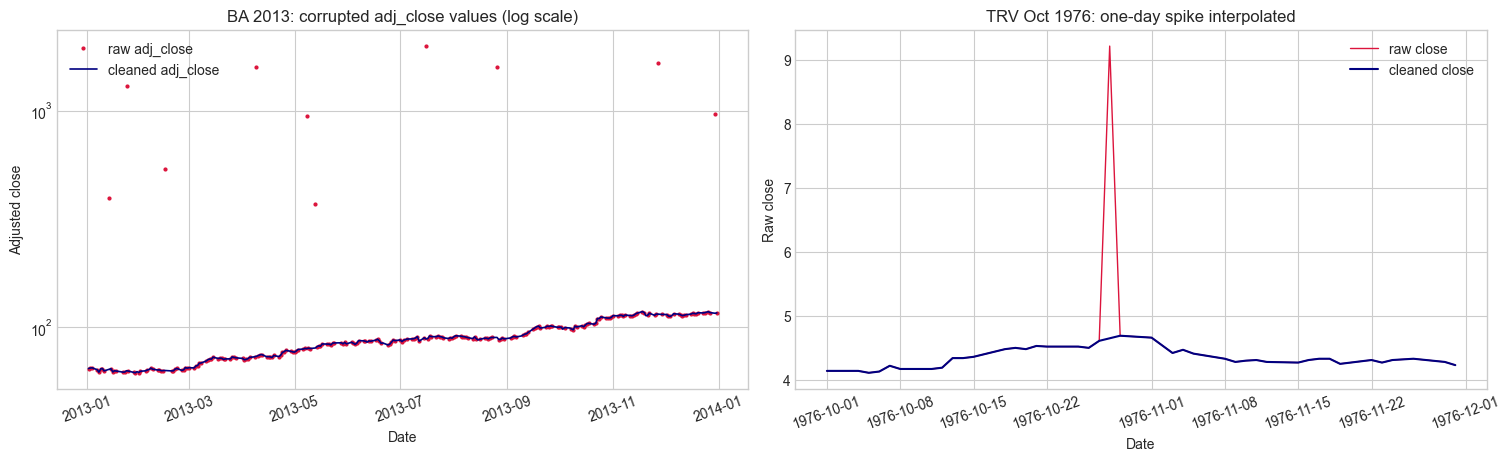

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), layout='constrained')

ba_raw = df[(df['ticker'] == 'BA') & df['ts'].between('2013-01-01', '2013-12-31')]
ba_clean = clean[(clean['ticker'] == 'BA') & clean['ts'].between('2013-01-01', '2013-12-31')]
axes[0].plot(ba_raw['ts'], ba_raw['adj_close'], '.', color='crimson', ms=4, label='raw adj_close')
axes[0].plot(ba_clean['ts'], ba_clean['adj_close'], color='navy', lw=1.2, label='cleaned adj_close')
axes[0].set_yscale('log')
axes[0].set(title='BA 2013: corrupted adj_close values (log scale)', xlabel='Date', ylabel='Adjusted close')
axes[0].legend()

trv_raw = df[(df['ticker'] == 'TRV') & df['ts'].between('1976-10-01', '1976-11-30')]
trv_clean = clean[(clean['ticker'] == 'TRV') & clean['ts'].between('1976-10-01', '1976-11-30')]
axes[1].plot(trv_raw['ts'], trv_raw['close'], color='crimson', lw=1, label='raw close')
axes[1].plot(trv_clean['ts'], trv_clean['close'], color='navy', lw=1.5, label='cleaned close')
axes[1].set(title='TRV Oct 1976: one-day spike interpolated', xlabel='Date', ylabel='Raw close')
axes[1].legend()
for ax in axes:
    ax.tick_params(axis='x', labelrotation=20)
plt.show()

## save `ohlc_hw_cleaned`

`ts` gets stored as `YYYY-MM-DD` text so the report's SQL date filters (`ts >= ?`) work as string comparisons. The repair flags and the original label go along with it. I also save the quarantined rows and the quality report as their own tables, so nothing just silently disappears. All of these go into the local working copy only.

In [27]:
flag_cols = ['open_repaired', 'high_repaired', 'low_repaired', 'close_repaired', 'spike_repaired',
             'adj_close_repaired', 'adj_close_source', 'volume_repaired', 'zero_volume_flag', 'extreme_return_flag']
out = clean[['ts', 'ticker', 'open', 'high', 'low', 'close', 'adj_close', 'volume', 'raw_ticker'] + flag_cols].copy()
out['ts'] = out['ts'].dt.strftime('%Y-%m-%d')
out['ticker'] = out['ticker'].astype(str)
out['raw_ticker'] = out['raw_ticker'].astype(str)
out.to_sql('ohlc_hw_cleaned', conn, if_exists='replace', index=False)

q_out = quarantine.drop(columns=['ref_close', 'ref_adj_close'], errors='ignore').copy()
q_out['ts'] = q_out['ts'].dt.strftime('%Y-%m-%d')
q_out.astype({'ticker': str, 'raw_ticker': str}).to_sql('ohlc_hw_quarantine', conn, if_exists='replace', index=False)

qr_out = quality_report.assign(issue_date=quality_report['issue_date'].dt.strftime('%Y-%m-%d'), ticker=quality_report['ticker'].astype(str))
qr_out.to_sql('ohlc_hw_quality_report', conn, if_exists='replace', index=False)
conn.execute('CREATE INDEX IF NOT EXISTS idx_cleaned_ticker_ts ON ohlc_hw_cleaned (ticker, ts)')
conn.commit()

In [28]:
# read it back and recheck from the db itself
check = pd.read_sql_query('SELECT * FROM ohlc_hw_cleaned', conn)
assert len(check) == len(clean)
assert check['ts'].str.fullmatch(r'\d{4}-\d{2}-\d{2}').all()
assert not check.duplicated(['ticker', 'ts']).any()
check['ts'] = pd.to_datetime(check['ts'])
assert validate_clean(check.sort_values(['ticker', 'ts']).reset_index(drop=True)).all()

raw_after = pd.read_sql_query('SELECT COUNT(*) AS n FROM ohlc_hw', conn)['n'].iloc[0]
assert raw_after == raw_row_count, 'raw table should be untouched'

summary = pd.read_sql_query('''
SELECT ticker, COUNT(*) AS rows, MIN(ts) AS first_date, MAX(ts) AS last_date,
       SUM(adj_close_repaired) AS adj_repaired
FROM ohlc_hw_cleaned GROUP BY ticker ORDER BY last_date, ticker''', conn)
display(summary)
print('saved ohlc_hw_cleaned:', len(check), 'rows,', check['ticker'].nunique(), 'tickers, latest date', check['ts'].max().date())
conn.close()

,ticker,rows,first_date,last_date,adj_repaired
0,AAPL,11050,1980-12-12,2024-10-18,904
1,AMGN,10421,1983-06-17,2024-10-18,790
2,AXP,13252,1972-04-03,2024-10-18,1027
3,BA,15784,1962-01-02,2024-10-18,1285
4,CAT,15808,1962-01-02,2024-10-18,1290
5,CRM,5117,2004-06-23,2024-10-18,415
6,CSCO,8734,1990-02-16,2024-10-18,685
7,GS,6408,1999-05-04,2024-10-18,502
8,HD,10861,1981-09-22,2024-10-18,818
9,HON,15808,1962-01-02,2024-10-18,1212


saved ohlc_hw_cleaned: 368246 rows, 30 tickers, latest date 2024-12-06


Note for later: the histories don't all end on the same day. 22 tickers stop on 2024-10-18 and only 8 go to 2024-12-06, so the reports have to show the actual coverage and not just the requested window.

## what I did (short version)

- tickers: 150 raw strings -> 30 tickers (html/whitespace/case). original label kept in `raw_ticker`
- 29,460 exact duplicates dropped, 0 conflicting keys
- 0 missing trading days vs the `ohlc` calendar (detector tested on an injected gap)
- adj_close: ~18k nulls + ~10k corrupted values (factor jumps) rebuilt from raw close x the same-date `ohlc` factor, flagged `adj_close_source = ohlc_factor_x_close`
- 3 TRV one-day spikes (doubles then reverts, flat OHLC, 0 volume) = data error, interpolated, flagged `spike_repaired`
- 5 rows with open = 0 on each ticker's first day: quarantined (nothing earlier to repair from)
- 3 sigma moves and zero volume days: kept, flagged for review only